# Acute Lymphoblastic Leukemia (ALL) Detection — CNN Classifier

Dataset: Kaggle `mehradaria/leukemia` — 4 classes (Benign, Pre, Early, Pro), `Original` image set.

In [7]:
# --- 1. Download dataset ---
!pip install opendatasets legacy-cgi
import os
from google.colab import userdata

# Securely load credentials from Colab's secret manager (the key icon on the left)
try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
except Exception as e:
    print("Please set KAGGLE_USERNAME and KAGGLE_KEY in your Colab Secrets (Left pane -> Key icon)")
    # Fallback to manual setup in code if you prefer not to use secrets:
    os.environ['KAGGLE_USERNAME'] = 'YOUR_KAGGLE_USERNAME'
    os.environ['KAGGLE_KEY'] = 'YOUR_KAGGLE_KEY'

import opendatasets as od

dataset_url = 'https://www.kaggle.com/datasets/mehradaria/leukemia'
od.download(dataset_url)

Please set KAGGLE_USERNAME and KAGGLE_KEY in your Colab Secrets (Left pane -> Key icon)
Skipping, found downloaded files in "./leukemia" (use force=True to force download)


In [8]:
# --- 2. Install dependencies ---
!pip install Keras
!pip install opendatasets

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

# Import from tensorflow's legacy keras interface
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

In [9]:
# --- 3. Unzip any .rar archives in the dataset ---
!pip install patool  ## unzip rar files

import os
from patoolib import extract_archive

def unzip_rar_files(folder_path):
    files = os.listdir(folder_path)
    for file in files:
        file_path = os.path.join(folder_path, file)
        if file.endswith(".rar"):
            try:
                extract_archive(file_path, outdir=folder_path)
                print(f"Successfully extracted: {file}")
            except Exception as e:
                print(f"Error extracting {file}: {e}")

# NOTE: this uses the 'Original' folder (not 'Segmented') — this is what
# produced the 92% result, unlike the Segmented-folder runs which topped out ~60%.
folder_path = "/content/leukemia/Original"
unzip_rar_files(folder_path)

In [10]:
# --- 4. Base directory and class folders ---
base_dir = '/content/leukemia/Original'

def get_folder_names(directory_path):
    folder_names = []
    for item in os.listdir(directory_path):
        item_path = os.path.join(directory_path, item)
        if os.path.isdir(item_path):
            if item != '.ipynb_checkpoints':
                folder_names.append(item)
    return folder_names

directory_path = "/content/leukemia/Original"
folders = get_folder_names(directory_path)
print("Folder Names:", folders)
# Expected: ['Benign', 'Pre', 'Early', 'Pro']

Folder Names: ['Benign', 'Pro', 'Early', 'Pre']


In [11]:
# --- 5. Train / val / test split (70 / 15 / 15) ---
train_dir = os.path.join(base_dir, 'train')
os.makedirs(train_dir, exist_ok=True)

val_dir = os.path.join(base_dir, 'val')
os.makedirs(val_dir, exist_ok=True)

test_dir = os.path.join(base_dir, 'test')
os.makedirs(test_dir, exist_ok=True)

import shutil

class_folders = folders
train_ratio = 0.7
val_ratio = 0.15
test_ratio = 0.15

for folder in class_folders:
    source_folder = os.path.join(base_dir, folder)
    train_dest = os.path.join(train_dir, folder)
    val_dest = os.path.join(val_dir, folder)
    test_dest = os.path.join(test_dir, folder)

    os.makedirs(train_dest, exist_ok=True)
    os.makedirs(val_dest, exist_ok=True)
    os.makedirs(test_dest, exist_ok=True)

    filenames = os.listdir(source_folder)
    num_files = len(filenames)

    num_train = int(num_files * train_ratio)
    num_val = int(num_files * val_ratio)

    train_files = filenames[:num_train]
    val_files = filenames[num_train:num_train + num_val]
    test_files = filenames[num_train + num_val:]

    for file in train_files:
        shutil.copy(os.path.join(source_folder, file), os.path.join(train_dest, file))
    for file in val_files:
        shutil.copy(os.path.join(source_folder, file), os.path.join(val_dest, file))
    for file in test_files:
        shutil.copy(os.path.join(source_folder, file), os.path.join(test_dest, file))

In [12]:
# --- 6. Data generators (augmentation on train only) ---
size = 224
batch_size = 64
target_size = (size, size)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest')

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=target_size,
    class_mode='categorical',
    batch_size=batch_size)

val_datagen = ImageDataGenerator(rescale=1./255)
val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=target_size,
    class_mode='categorical',
    batch_size=batch_size,
    shuffle=False)

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=target_size,
    class_mode='categorical',
    batch_size=batch_size,
    shuffle=False)

# Expected: Found 2277 images (train) / 486 (val) / 493 (test), belonging to 4 classes.

Found 2277 images belonging to 4 classes.
Found 486 images belonging to 4 classes.
Found 493 images belonging to 4 classes.


In [13]:
test_labels = np.array(test_generator.labels)

In [14]:
# --- 7. CNN model: 6 Conv2D+MaxPooling blocks (64,64,128,128,256,256) ---
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix

model = Sequential([
    Conv2D(64, (3, 3), activation='relu', input_shape=(size, size, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(256, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(256, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(len(class_folders), activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,279,044 (4.88 MB)

 Trainable params: 1,279,044 (4.88 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 261s 7s/step - accuracy: 0.3312 - loss: 1.3172 - val_accuracy: 0.4933 - val_loss: 1.0785
Epoch 2/25
 1/35 ━━━━━━━━━━━━━━━━━━━━ 3:50 7s/step - accuracy: 0.5156 - loss: 1.0454

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 389ms/step - accuracy: 0.5156 - loss: 1.0454 - val_accuracy: 0.3326 - val_loss: 1.1665
Epoch 3/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 262s 7s/step - accuracy: 0.6647 - loss: 0.8601 - val_accuracy: 0.7143 - val_loss: 0.6390
Epoch 4/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 21s 423ms/step - accuracy: 0.7188 - loss: 0.7608 - val_accuracy: 0.7344 - val_loss: 0.5983
Epoch 5/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 322s 8s/step - accuracy: 0.7506 - loss: 0.5898 - val_accuracy: 0.8036 - val_loss: 0.4464
Epoch 6/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 21s 408ms/step - accuracy: 0.7031 - loss: 0.5777 - val_accuracy: 0.8013 - val_loss: 0.4423
Epoch 7/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 262s 7s/step - accuracy: 0.8016 - loss: 0.4709 - val_accuracy: 0.8170 - val_loss: 0.3921
Epoch 8/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 21s 410ms/step - accuracy: 0.8594 - loss: 0.3481 - val_accuracy: 0.8192 - val_loss: 0.3926
Epoch 9/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 253s 7s/step - accuracy: 0.8405 - loss: 0.4313 - val_accuracy: 0.8616 - val_

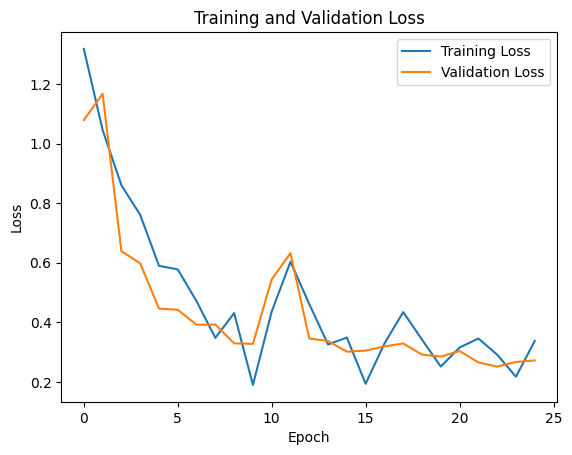

In [15]:
# --- 8. Train for 25 epochs ---
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    epochs=25,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size)

val_loss, val_accuracy = model.evaluate(val_generator)
print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [16]:
# --- 9. Evaluate on the held-out test set ---
test_loss, test_accuracy = model.evaluate(test_generator)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

y_pred = model.predict(test_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
true_classes = test_generator.classes

8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.9148 - loss: 0.2561
Test Loss: 0.256069540977478
Test Accuracy: 0.9148073196411133
8/8 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step


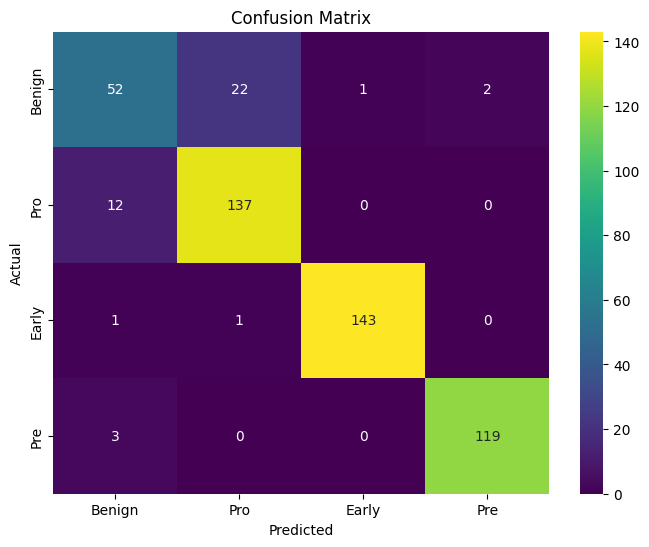

Precision: 0.8616352201257862
Recall: 0.9194630872483222
F1 Score: 0.8896103896103895


In [17]:
# --- 10. Confusion matrix + precision/recall/F1 ---
import seaborn as sns

predictions = model.predict(test_generator)
predicted_labels = np.argmax(predictions, axis=1)

confusion_mtx = confusion_matrix(test_labels, predicted_labels)
classes = class_folders

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_mtx, annot=True, fmt='d', cmap='viridis',
            xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

cm = confusion_mtx
TN = cm[0][0]
FP = cm[0][1]
FN = cm[1][0]
TP = cm[1][1]

precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1_score = 2 * (precision * recall) / (precision + recall)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1_score)